# Exercise P6.1: Correlation Analysis & Profiling
### STAT 540 — Week 6


## Overview

In this exercise, you will compute correlation matrices, compare Pearson vs Spearman, and generate an automated EDA report.

## Task 1: Correlation Matrix and Heatmap

/usr/local/lib/python3.13/dist-packages/sklearn/datasets/_openml.py:323: UserWarning: Multiple active versions of the dataset matching the name diamonds exist. Versions may be fundamentally different, returning version 1. Available versions:
- version 1, status: active
  url: https://www.openml.org/search?type=data&id=42225
- version 2, status: active
  url: https://www.openml.org/search?type=data&id=43998

  warn(warning_msg)


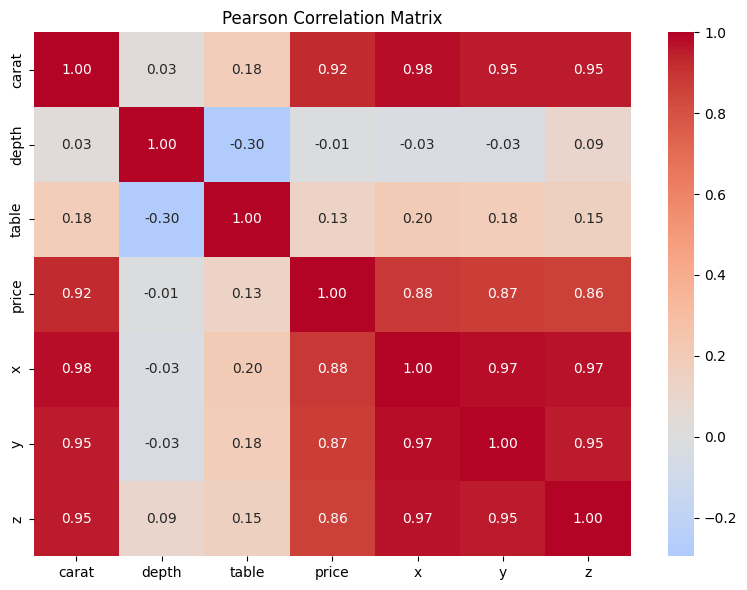

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load a dataset (diamonds, penguins, or your choice)
from sklearn.datasets import fetch_openml
diamonds = fetch_openml(name="diamonds", as_frame=True, parser="auto").frame

# Compute Pearson correlation
corr_pearson = diamonds.select_dtypes("number").corr(method="pearson")

# Visualize
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_pearson, annot=True, cmap="coolwarm", center=0, fmt=".2f", ax=ax)
ax.set_title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

## Task 2: Pearson vs Spearman Comparison

In [2]:
# Compute Spearman correlation
corr_spearman = diamonds.select_dtypes("number").corr(method="spearman")

# Find pairs where Pearson and Spearman differ most
diff = (corr_pearson - corr_spearman).abs()
# Get the largest differences (excluding diagonal)
import numpy as np
np.fill_diagonal(diff.values, 0)
max_diff_idx = np.unravel_index(diff.values.argmax(), diff.shape)
col1, col2 = diff.columns[max_diff_idx[0]], diff.columns[max_diff_idx[1]]
print(f"Largest difference between Pearson and Spearman: {col1} vs {col2}")
print(f"  Pearson:  {corr_pearson.loc[col1, col2]:.3f}")
print(f"  Spearman: {corr_spearman.loc[col1, col2]:.3f}")

Largest difference between Pearson and Spearman: price vs y
  Pearson:  0.865
  Spearman: 0.963


**Your turn:** For the pair with the largest Pearson-Spearman difference, explain why they might differ. What does this tell you about the relationship?

> The pair with the largest difference is **`price` vs `y`** (where Pearson = 0.865 and Spearman = 0.963). They differ because Pearson measures strictly linear relationships, whereas Spearman measures monotonic relationships. Because diamond price scales non-linearly (exponentially or quadratically) with size dimensions like `y`, the relationship is highly predictable (monotonic, hence a very high Spearman rank correlation of 0.963) but not perfectly straight (linear, hence a lower Pearson correlation of 0.865). Additionally, Pearson correlation is highly sensitive to extreme outliers and skewness in the data. Diamond prices are heavily right-skewed, which weakens Pearson's coefficient, whereas Spearman is rank-based and much more robust to these distribution characteristics.

In [4]:
# Install ydata-profiling
!pip install -q ydata-profiling

# Generate a minimal profiling report
from ydata_profiling import ProfileReport

profile = ProfileReport(diamonds.head(5000), title="Diamond EDA Report", minimal=True)
profile.to_file("diamond_eda_report.html")
print("Report saved to diamond_eda_report.html")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 64.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 41.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 5.8 MB/s eta 0:00:00


/tmp/ipykernel_3465/1535238443.py:5: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport
/usr/local/lib/python3.13/dist-packages/ydata_profiling/utils/dataframe.py:137: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={"index": "df_index"}, inplace=True)


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 10/10 [00:00<00:00, 135.60it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Report saved to diamond_eda_report.html


**Your turn:** Open the report and identify one finding the automated tool flagged that you did not notice in your manual EDA:

> *[Your finding]*

## Task 4: Simpson's Paradox Check

In [5]:
# Check: does the carat-price correlation change within cut groups?
print("Overall correlation (carat vs price):", diamonds["carat"].corr(diamonds["price"]).round(3))

for cut in diamonds["cut"].unique():
    subset = diamonds[diamonds["cut"] == cut]
    r = subset["carat"].corr(subset["price"]).round(3)
    print(f"  {cut}: {r}")

Overall correlation (carat vs price): 0.922
  Ideal: 0.931
  Premium: 0.925
  Good: 0.922
  Very Good: 0.926
  Fair: 0.859


**Your turn:** Does the relationship change across groups? Is this an example of Simpson's Paradox?

> The relationship changes, but only slightly. The correlation between `carat` and `price` remains extremely strong across all quality groups (ranging from `0.859` for Fair cuts to `0.931` for Ideal cuts). This is not an example of Simpson's Paradox, however, as it is characterized by an association or trend that completely **reverses direction** (e.g., goes from positive to negative) when subgroups are combined. In this case, the trend remains highly positive both within each individual subgroup and in the overall aggregated population (overall correlation = `0.922`). Since no reversal occurs, this is not Simpson's Paradox.

```bash
git add week06/exercises/P6.1*
git commit -m "Complete Exercise P6.1: Correlation analysis and profiling"
git push origin main
```